#  Istanbul Apartment Prices 2026 — Comprehensive EDA

**Can we decode what drives apartment prices in one of the world's most dynamic real estate markets?**

Istanbul straddles two continents, houses 16 million people, and features a real estate market that ranges from centuries-old neighborhoods to brand-new skyscraper complexes. This notebook explores **24,767 apartment listings** scraped from Hepsiemlak.com (Turkey's largest real estate platform) to uncover the hidden patterns behind Istanbul's housing prices.

---

###  Table of Contents

1. [Setup & Data Loading](#1)
2. [First Look at the Data](#2)
3. [Data Quality Assessment](#3)
4. [Price Distribution & Outliers](#4)
5. [Location Analysis — Where Is the Money?](#5)
6. [Size & Room Analysis](#6)
7. [Building Characteristics](#7)
8. [Feature Deep Dive — What Else Matters?](#8)
9. [Correlation & Feature Relationships](#9)
10. [Key Findings & Conclusions](#10)

---

<a id='1'></a>
## 1. 🔧 Setup & Data Loading

We'll use a combination of **Matplotlib/Seaborn** for polished static charts and **Plotly** for interactive exploration.

In [3]:
# Core
import pandas as pd
import numpy as np

# Static visualization
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

# Interactive visualization
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Utilities
import warnings
warnings.filterwarnings('ignore')

# Style configuration
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['figure.dpi'] = 100
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.titleweight'] = 'bold'

# Custom color palette for Istanbul theme
COLORS = {
    'primary': '#DC3545',     # Turkish red
    'secondary': '#1A5276',   # Bosphorus blue
    'accent': '#F39C12',      # Gold
    'dark': '#2C3E50',        # Dark slate
    'light': '#ECF0F1',       # Light gray
    'gradient': ['#DC3545', '#E74C3C', '#F39C12', '#F1C40F', '#27AE60']
}

PALETTE = sns.color_palette([COLORS['primary'], COLORS['secondary'], COLORS['accent'], '#27AE60', '#8E44AD', '#E67E22'])

print('✅ Libraries loaded successfully!')

✅ Libraries loaded successfully!


In [4]:
# Load dataset
df = pd.read_csv('/Users/mirza/Desktop/BAU/DataMining/project/data/istanbul_apartment_prices_2026.csv')

print(f'Dataset loaded: {df.shape[0]:,} rows × {df.shape[1]} columns')
print(f'Memory usage: {df.memory_usage(deep=True).sum() / 1024**2:.1f} MB')

Dataset loaded: 24,767 rows × 30 columns
Memory usage: 24.6 MB


<a id='2'></a>
## 2. 🔍 First Look at the Data

Before diving into analysis, let's understand what we're working with. Each row represents a single apartment listing for sale in Istanbul.

In [40]:
# Preview the first 5 rows
df.head()

,listing_id,price,price_per_sqm,district,neighborhood,rooms,halls,total_rooms,gross_sqm,net_sqm,...,usage_status,is_in_complex,complex_name,orientation,maintenance_fee,credit_eligible,deed_status,exchange,last_updated,scraped_at
0,54895-1121,15900000,165625.00,Adalar,Maden,3,1,4,138.0,96.0,...,Vacant,0,NaN,"North, South, East, West",2500.0,Not Eligible,Land Title,No,2026-03-11,2026-03-14T20:38:29
1,54895-1103,40000000,266666.67,Adalar,Nizam,4,1,5,199.0,150.0,...,Vacant,1,NaN,"North, South, East, West",10000.0,Eligible,Construction Easement,No,2026-03-05,2026-03-14T20:38:36
2,54895-1148,17850000,220370.37,Adalar,Nizam,2,1,3,107.0,81.0,...,Vacant,0,NaN,"North, East, West",1000.0,Eligible,Condominium Title,No,2026-03-05,2026-03-14T20:38:47
3,12854-258,16000000,81632.65,Adalar,Heybeliada,3,1,4,200.0,196.0,...,Owner-occupied,0,NaN,"North, West",NaN,Eligible,Condominium Title,No,2026-03-14,2026-03-14T20:38:56
4,121334-99,14000000,96551.72,Adalar,Nizam,4,1,5,160.0,145.0,...,Vacant,0,NaN,NaN,400.0,Eligible,Condominium Title,No,2026-03-14,2026-03-14T20:39:04


In [41]:
# Dataset shape and column info
print(f'Rows:    {df.shape[0]:>10,}')
print(f'Columns: {df.shape[1]:>10}')
print(f'\n{"="*50}')
print(f'{"Column":<25} {"Type":<15} {"Non-Null":>10} {"Null %":>8}')
print(f'{"="*50}')

for col in df.columns:
    dtype = str(df[col].dtype)
    non_null = df[col].notna().sum()
    null_pct = df[col].isna().mean() * 100
    marker = ' ⚠️' if null_pct > 50 else ' ⚡' if null_pct > 20 else ''
    print(f'{col:<25} {dtype:<15} {non_null:>10,} {null_pct:>7.1f}%{marker}')

Rows:        24,767
Columns:         30

Column                    Type              Non-Null   Null %
listing_id                str                 24,767     0.0%
price                     int64               24,767     0.0%
price_per_sqm             float64             24,767     0.0%
district                  str                 24,767     0.0%
neighborhood              str                 24,767     0.0%
rooms                     int64               24,767     0.0%
halls                     int64               24,767     0.0%
total_rooms               int64               24,767     0.0%
gross_sqm                 float64             24,767     0.0%
net_sqm                   float64             24,767     0.0%
floor                     float64             22,850     7.7%
floor_category            str                  7,395    70.1% ⚠️
total_floors              float64             24,766     0.0%
building_age              int64               24,767     0.0%
building_type             

In [42]:
# Descriptive statistics for numeric columns
df.describe().round(2)

,price,price_per_sqm,rooms,halls,total_rooms,gross_sqm,net_sqm,floor,total_floors,building_age,bathroom_count,is_in_complex,maintenance_fee
count,2.476700e+04,2.476700e+04,24767.00,24767.00,24767.00,24767.00,24767.00,22850.00,24766.00,24767.00,24532.00,24767.00,9002.00
mean,1.342985e+07,1.326089e+05,2.58,1.09,3.67,126.32,107.49,2.80,6.62,11.33,1.50,0.22,3778.89
std,1.414843e+08,1.967747e+06,1.26,0.45,1.45,58.21,49.91,3.23,6.72,13.10,0.78,0.42,114997.71
min,2.400000e+04,2.926800e+02,1.00,0.00,1.00,1.00,1.00,-3.00,1.00,0.00,1.00,0.00,1.00
25%,4.500000e+06,4.861111e+04,2.00,1.00,3.00,90.00,75.00,1.00,4.00,0.00,1.00,0.00,200.00
50%,6.750000e+06,7.250000e+04,2.00,1.00,3.00,110.00,95.00,2.00,5.00,6.00,1.00,0.00,400.00
75%,1.150000e+07,1.138461e+05,3.00,1.00,4.00,146.00,125.00,4.00,7.00,20.00,2.00,0.00,1500.00
max,1.150000e+10,1.600000e+08,114.00,20.00,117.00,909.00,900.00,20.00,450.00,400.00,21.00,1.00,9000000.00


In [43]:
# Categorical columns overview
cat_cols = df.select_dtypes(include='object').columns

print(f'{"Column":<25} {"Unique":>8} {"Top Value":<30} {"Freq":>6}')
print('='*75)

for col in cat_cols:
    nunique = df[col].nunique()
    top_val = df[col].mode()[0] if not df[col].mode().empty else 'N/A'
    top_freq = df[col].value_counts().iloc[0] if nunique > 0 else 0
    print(f'{col:<25} {nunique:>8} {str(top_val)[:29]:<30} {top_freq:>6,}')

Column                      Unique Top Value                        Freq
listing_id                   24767 0-12794009                          1
district                        38 Bahçelievler                    1,191
neighborhood                   583 Cumhuriyet                        638
floor_category                  16 Garden Floor                    1,840
building_type                    7 Reinforced Concrete            10,062
building_condition               3 Second-hand                     7,299
heating_type                    15 Combi Boiler                   18,470
fuel_type                        4 Natural Gas                    10,733
furnished                        2 Unfurnished                    22,582
usage_status                     4 Vacant                         14,015
complex_name                  1976 Ağaoğlu Maslak 1453                64
orientation                     16 South                           4,682
credit_eligible                  3 Eligible        

**Key observations from the first look:**
- **24,767 listings** across **38 districts** and **583 neighborhoods** — solid coverage of Istanbul
- Price ranges from ₺24K to ₺11.5B — clearly some extreme outliers to handle
- Several columns have >50% missing values (`building_type`, `building_condition`, `fuel_type`, `complex_name`, `maintenance_fee`) — we'll need to account for this
- Core features (`price`, `rooms`, `gross_sqm`, `district`) have zero or near-zero missing values — great for analysis

<a id='3'></a>
## 3. 🧹 Data Quality Assessment

Let's visualize the data quality to understand what we can rely on and what needs careful handling.

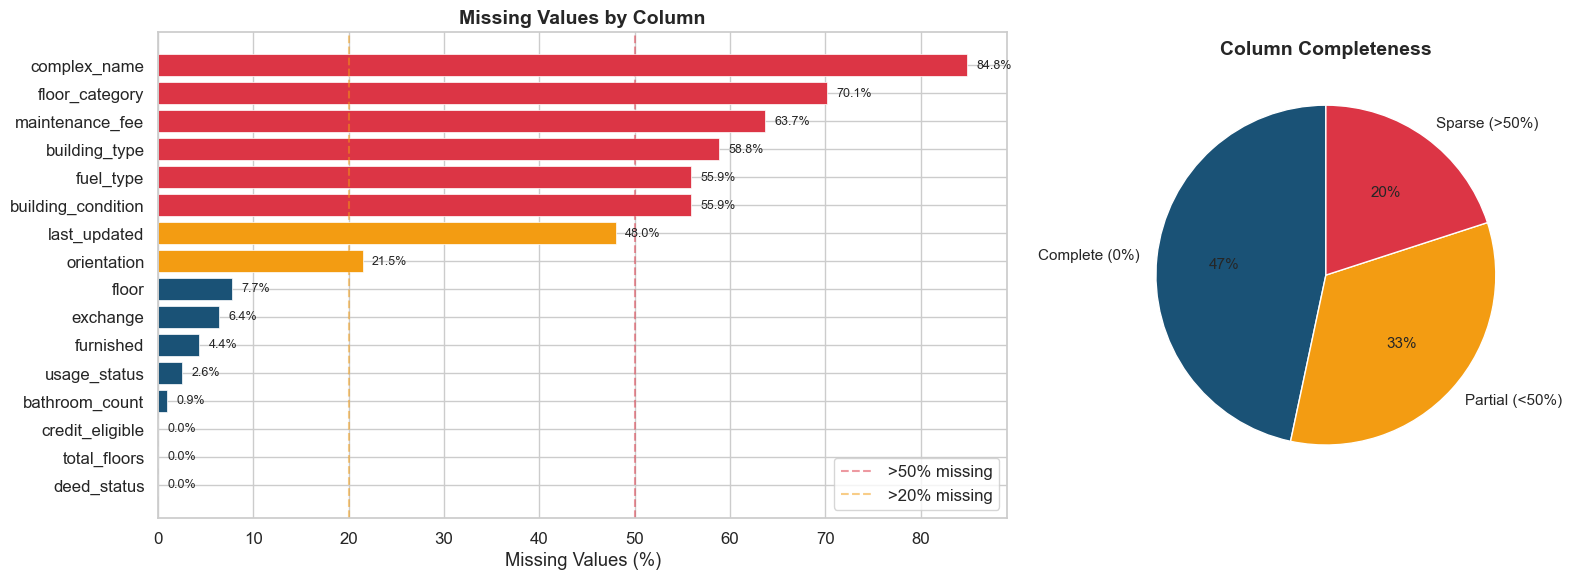


📊 14 columns fully complete | 10 partially missing | 6 more than half missing


In [44]:
# Missing values heatmap
fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={'width_ratios': [2, 1]})

# Left: Missing values bar chart (sorted)
null_pct = (df.isnull().sum() / len(df) * 100).sort_values(ascending=True)
null_pct = null_pct[null_pct > 0]

colors = [COLORS['primary'] if v > 50 else COLORS['accent'] if v > 20 else COLORS['secondary'] for v in null_pct]

axes[0].barh(null_pct.index, null_pct.values, color=colors, edgecolor='white', linewidth=0.5)
axes[0].set_xlabel('Missing Values (%)')
axes[0].set_title('Missing Values by Column')
axes[0].axvline(x=50, color=COLORS['primary'], linestyle='--', alpha=0.5, label='>50% missing')
axes[0].axvline(x=20, color=COLORS['accent'], linestyle='--', alpha=0.5, label='>20% missing')
axes[0].legend(loc='lower right')

for i, (val, name) in enumerate(zip(null_pct.values, null_pct.index)):
    axes[0].text(val + 1, i, f'{val:.1f}%', va='center', fontsize=9)

# Right: Completeness pie
complete_cols = (df.isnull().sum() == 0).sum()
partial_cols = ((df.isnull().sum() > 0) & (df.isnull().sum() / len(df) < 0.5)).sum()
sparse_cols = (df.isnull().sum() / len(df) >= 0.5).sum()

wedges, texts, autotexts = axes[1].pie(
    [complete_cols, partial_cols, sparse_cols],
    labels=['Complete (0%)', 'Partial (<50%)', 'Sparse (>50%)'],
    colors=[COLORS['secondary'], COLORS['accent'], COLORS['primary']],
    autopct='%1.0f%%', startangle=90, textprops={'fontsize': 11}
)
axes[1].set_title('Column Completeness')

plt.tight_layout()
plt.show()

print(f'\n📊 {complete_cols} columns fully complete | {partial_cols} partially missing | {sparse_cols} more than half missing')

In [45]:
# Check for potential duplicates
dup_ids = df['listing_id'].duplicated().sum()
print(f'Duplicate listing IDs: {dup_ids}')
print(f'Unique listings: {df["listing_id"].nunique():,}')
print(f'\n✅ No duplicates — every row is a unique listing.')

Duplicate listing IDs: 0
Unique listings: 24,767

✅ No duplicates — every row is a unique listing.


**Data quality summary:**
- ✅ **No duplicates** — clean unique listings
- ✅ **Core features complete** — price, location, rooms, sqm all have 0% missing
- ⚠️ **6 columns have >50% missing** — these are optional listing fields that sellers often skip (building type, fuel type, maintenance fee, etc.)
- 💡 **Strategy**: We'll use all data for general analysis, and clearly note when analyzing sparse columns that the sample is limited

<a id='4'></a>
## 4. 💰 Price Distribution & Outliers

Price is our most important feature. Let's understand its distribution before anything else.

In [46]:
# Price statistics
print('💰 PRICE STATISTICS (Turkish Lira - TRY)')
print('='*45)
print(f'{"Mean:":<20} ₺{df["price"].mean():>15,.0f}')
print(f'{"Median:":<20} ₺{df["price"].median():>15,.0f}')
print(f'{"Std Dev:":<20} ₺{df["price"].std():>15,.0f}')
print(f'{"Min:":<20} ₺{df["price"].min():>15,.0f}')
print(f'{"25th percentile:":<20} ₺{df["price"].quantile(0.25):>15,.0f}')
print(f'{"75th percentile:":<20} ₺{df["price"].quantile(0.75):>15,.0f}')
print(f'{"99th percentile:":<20} ₺{df["price"].quantile(0.99):>15,.0f}')
print(f'{"Max:":<20} ₺{df["price"].max():>15,.0f}')
print(f'\n⚠️ Mean (₺{df["price"].mean()/1e6:.1f}M) >> Median (₺{df["price"].median()/1e6:.1f}M) → heavily right-skewed')

💰 PRICE STATISTICS (Turkish Lira - TRY)
Mean:                ₺     13,429,846
Median:              ₺      6,750,000
Std Dev:             ₺    141,484,342
Min:                 ₺         24,000
25th percentile:     ₺      4,500,000
75th percentile:     ₺     11,500,000
99th percentile:     ₺     76,000,000
Max:                 ₺ 11,500,000,000

⚠️ Mean (₺13.4M) >> Median (₺6.8M) → heavily right-skewed


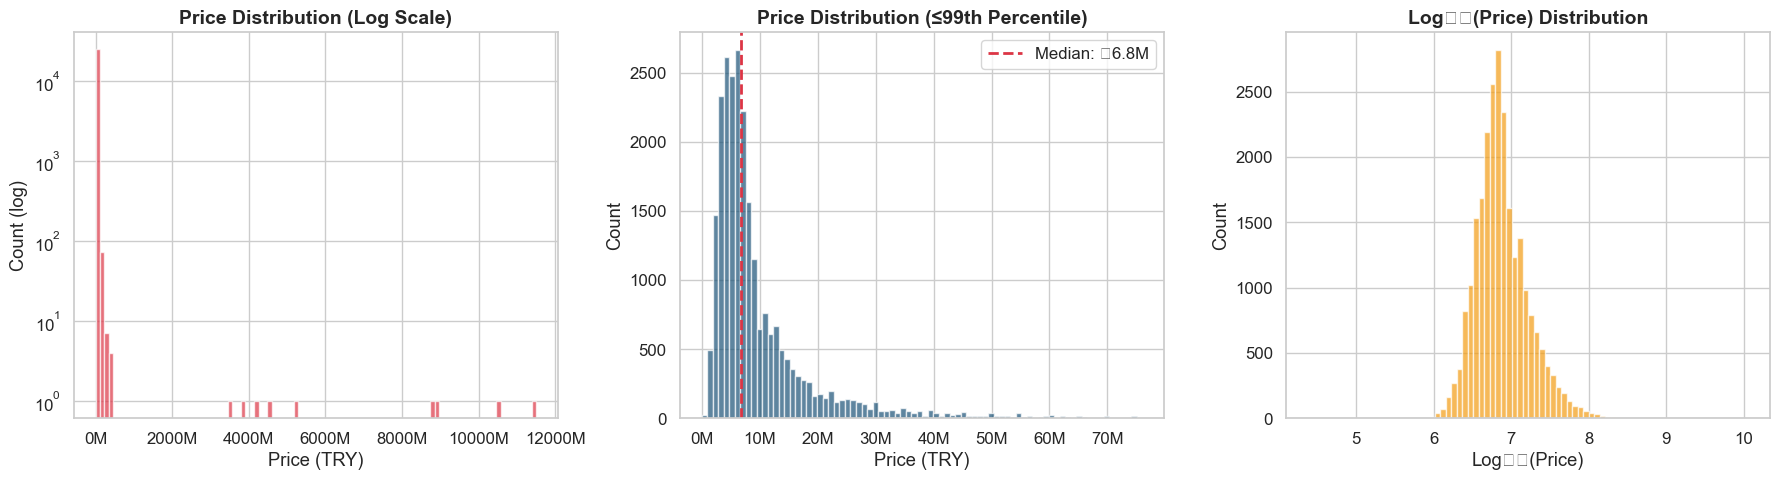


📊 The log-transformed price shows a near-normal distribution — useful for regression models.


In [47]:
# Price distribution — full range vs focused view
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Full distribution (log scale)
axes[0].hist(df['price'], bins=100, color=COLORS['primary'], alpha=0.7, edgecolor='white')
axes[0].set_yscale('log')
axes[0].set_title('Price Distribution (Log Scale)')
axes[0].set_xlabel('Price (TRY)')
axes[0].set_ylabel('Count (log)')
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x/1e6:.0f}M'))

# Focused: 99th percentile
p99 = df['price'].quantile(0.99)
df_focus = df[df['price'] <= p99]

axes[1].hist(df_focus['price'], bins=80, color=COLORS['secondary'], alpha=0.7, edgecolor='white')
axes[1].axvline(df_focus['price'].median(), color=COLORS['primary'], linestyle='--', linewidth=2, label=f'Median: ₺{df_focus["price"].median()/1e6:.1f}M')
axes[1].set_title('Price Distribution (≤99th Percentile)')
axes[1].set_xlabel('Price (TRY)')
axes[1].set_ylabel('Count')
axes[1].legend()
axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x/1e6:.0f}M'))

# Log-transformed
axes[2].hist(np.log10(df['price']), bins=80, color=COLORS['accent'], alpha=0.7, edgecolor='white')
axes[2].set_title('Log₁₀(Price) Distribution')
axes[2].set_xlabel('Log₁₀(Price)')
axes[2].set_ylabel('Count')

plt.tight_layout()
plt.show()

print(f'\n📊 The log-transformed price shows a near-normal distribution — useful for regression models.')

In [48]:
# Outlier analysis
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df['price'] < lower_bound) | (df['price'] > upper_bound)]
extreme_high = df[df['price'] > 500_000_000]  # > 500M TRY

print(f'IQR-based outlier detection:')
print(f'  Q1: ₺{Q1:,.0f} | Q3: ₺{Q3:,.0f} | IQR: ₺{IQR:,.0f}')
print(f'  Upper bound: ₺{upper_bound:,.0f}')
print(f'  Outliers (IQR method): {len(outliers):,} ({len(outliers)/len(df)*100:.1f}%)')
print(f'\n  Extreme outliers (>₺500M): {len(extreme_high)} — likely data entry errors')
print(f'\n💡 For most analyses below, we\'ll focus on the ≤99th percentile to avoid distortion.')

IQR-based outlier detection:
  Q1: ₺4,500,000 | Q3: ₺11,500,000 | IQR: ₺7,000,000
  Upper bound: ₺22,000,000
  Outliers (IQR method): 2,357 (9.5%)

  Extreme outliers (>₺500M): 9 — likely data entry errors

💡 For most analyses below, we'll focus on the ≤99th percentile to avoid distortion.


In [24]:
# Interactive: Price per square meter distribution by district
fig = px.box(
    df[df['price_per_sqm'] <= df['price_per_sqm'].quantile(0.99)],
    x='district',
    y='price_per_sqm',
    color='district',
    title='Price per m² Distribution by District (≤99th Percentile)',
    labels={'price_per_sqm': 'Price per m² (TRY)', 'district': 'District'},
    color_discrete_sequence=px.colors.qualitative.Set3
)

fig.update_layout(
    showlegend=False,
    xaxis_tickangle=-45,
    width=850, height=500,
    template='plotly_white',
    xaxis_title='',
    font=dict(size=11)
)

fig.show(renderer='notebook')

[interactive Plotly figure — run the notebook to view]

[interactive Plotly figure — run the notebook to view]

**Price insights:**
- The median apartment costs **₺6.75M** (~$190K USD) — prices are heavily right-skewed
- **Log-transformation** reveals a near-normal distribution → great for regression
- ~5% of listings are IQR-based outliers; 9 listings above ₺500M are likely errors
- **Price per m² varies dramatically** across districts — location is clearly a dominant factor

<a id='5'></a>
## 5. 📍 Location Analysis — Where Is the Money?

Istanbul's 38 districts span from historic peninsulas to suburban developments. Where are the most (and least) expensive apartments?

In [25]:
# Listing count by district
district_counts = df['district'].value_counts()

fig = px.bar(
    x=district_counts.index,
    y=district_counts.values,
    title='Number of Listings by District',
    labels={'x': 'District', 'y': 'Number of Listings'},
    color=district_counts.values,
    color_continuous_scale='RdYlBu_r'
)

fig.update_layout(
    xaxis_tickangle=-45,
    width=850, height=500,
    template='plotly_white',
    coloraxis_showscale=False
)

fig.show(renderer='notebook')

[interactive Plotly figure — run the notebook to view]

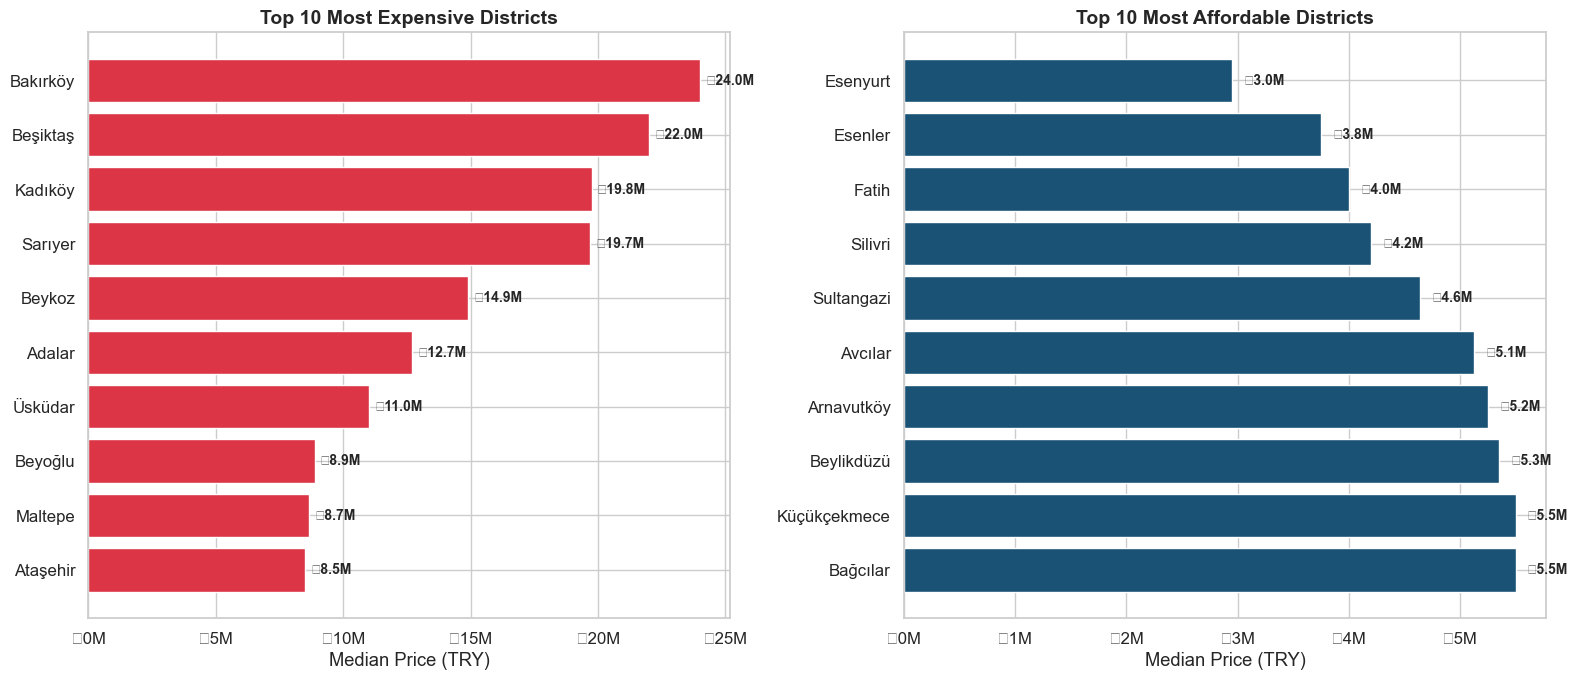


📊 The most expensive district (Bakırköy) is 8.1x pricier than the cheapest (Esenyurt)


In [51]:
# Median price by district — Top 10 most and least expensive
district_price = df.groupby('district')['price'].median().sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Most expensive
top10 = district_price.head(10)
bars1 = axes[0].barh(top10.index[::-1], top10.values[::-1], color=COLORS['primary'], edgecolor='white')
axes[0].set_title('Top 10 Most Expensive Districts')
axes[0].set_xlabel('Median Price (TRY)')
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'₺{x/1e6:.0f}M'))
for bar, val in zip(bars1, top10.values[::-1]):
    axes[0].text(val + 200000, bar.get_y() + bar.get_height()/2, f'₺{val/1e6:.1f}M', va='center', fontsize=10, fontweight='bold')

# Least expensive
bottom10 = district_price.tail(10)
bars2 = axes[1].barh(bottom10.index, bottom10.values, color=COLORS['secondary'], edgecolor='white')
axes[1].set_title('Top 10 Most Affordable Districts')
axes[1].set_xlabel('Median Price (TRY)')
axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'₺{x/1e6:.0f}M'))
for bar, val in zip(bars2, bottom10.values):
    axes[1].text(val + 100000, bar.get_y() + bar.get_height()/2, f'₺{val/1e6:.1f}M', va='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

ratio = district_price.iloc[0] / district_price.iloc[-1]
print(f'\n📊 The most expensive district ({district_price.index[0]}) is {ratio:.1f}x pricier than the cheapest ({district_price.index[-1]})')

In [26]:
# Median price per m² by district — better comparison
district_psqm = df.groupby('district')['price_per_sqm'].median().sort_values(ascending=False)

fig = px.bar(
    x=district_psqm.index,
    y=district_psqm.values,
    title='Median Price per m² by District — The Real Cost of Location',
    labels={'x': 'District', 'y': 'Median Price per m² (TRY)'},
    color=district_psqm.values,
    color_continuous_scale='RdYlBu_r'
)

fig.update_layout(
    xaxis_tickangle=-45,
    width=850, height=500,
    template='plotly_white',
    coloraxis_colorbar_title='TRY/m²'
)

fig.show(renderer='notebook')

[interactive Plotly figure — run the notebook to view]

In [27]:
# Top 20 most expensive neighborhoods
neighborhood_price = df.groupby(['district', 'neighborhood']).agg(
    median_price=('price', 'median'),
    median_psqm=('price_per_sqm', 'median'),
    count=('price', 'count')
).reset_index()

# Filter neighborhoods with at least 10 listings for reliability
neighborhood_price = neighborhood_price[neighborhood_price['count'] >= 10]
top_neighborhoods = neighborhood_price.nlargest(20, 'median_price')

top_neighborhoods['label'] = top_neighborhoods['neighborhood'] + ' (' + top_neighborhoods['district'] + ')'

fig = px.bar(
    top_neighborhoods.sort_values('median_price'),
    x='median_price',
    y='label',
    orientation='h',
    title='Top 20 Most Expensive Neighborhoods (min. 10 listings)',
    labels={'median_price': 'Median Price (TRY)', 'label': ''},
    color='district',
    hover_data=['count', 'median_psqm']
)

fig.update_layout(
    width=850, height=500,
    template='plotly_white',
    xaxis_title='Median Price (TRY)',
    legend_title='District'
)

fig.show(renderer='notebook')

[interactive Plotly figure — run the notebook to view]

In [28]:
# District-level summary: price vs listing volume (bubble chart)
district_summary = df.groupby('district').agg(
    median_price=('price', 'median'),
    median_psqm=('price_per_sqm', 'median'),
    count=('price', 'count'),
    median_sqm=('gross_sqm', 'median')
).reset_index()

fig = px.scatter(
    district_summary,
    x='median_psqm',
    y='median_price',
    size='count',
    color='median_sqm',
    hover_name='district',
    title='District Overview: Price vs Price/m² (bubble size = listing count)',
    labels={
        'median_psqm': 'Median Price per m² (TRY)',
        'median_price': 'Median Price (TRY)',
        'median_sqm': 'Median m²',
        'count': 'Listings'
    },
    color_continuous_scale='Viridis',
    size_max=40
)

fig.update_layout(width=850, height=500, template='plotly_white')
fig.show(renderer='notebook')

[interactive Plotly figure — run the notebook to view]

**Location insights:**
- **Bakırköy** leads with a median price of ₺24M, followed by **Beşiktaş** (₺22M) and **Kadıköy** (₺19.75M) — all established, central districts
- **Esenyurt** is the most affordable district (₺2.95M median) — a massive suburban development area
- The price gap between the most and least expensive districts is roughly **8x**
- **Bahçelievler, Beylikdüzü, Küçükçekmece** have the most listings (~1,200 each) — high supply areas
- The bubble chart reveals a clear premium cluster (Bakırköy, Beşiktaş, Kadıköy, Sarıyer) separated from the rest

<a id='6'></a>
## 6. 📐 Size & Room Analysis

How big are Istanbul apartments, and how do room configurations affect price?

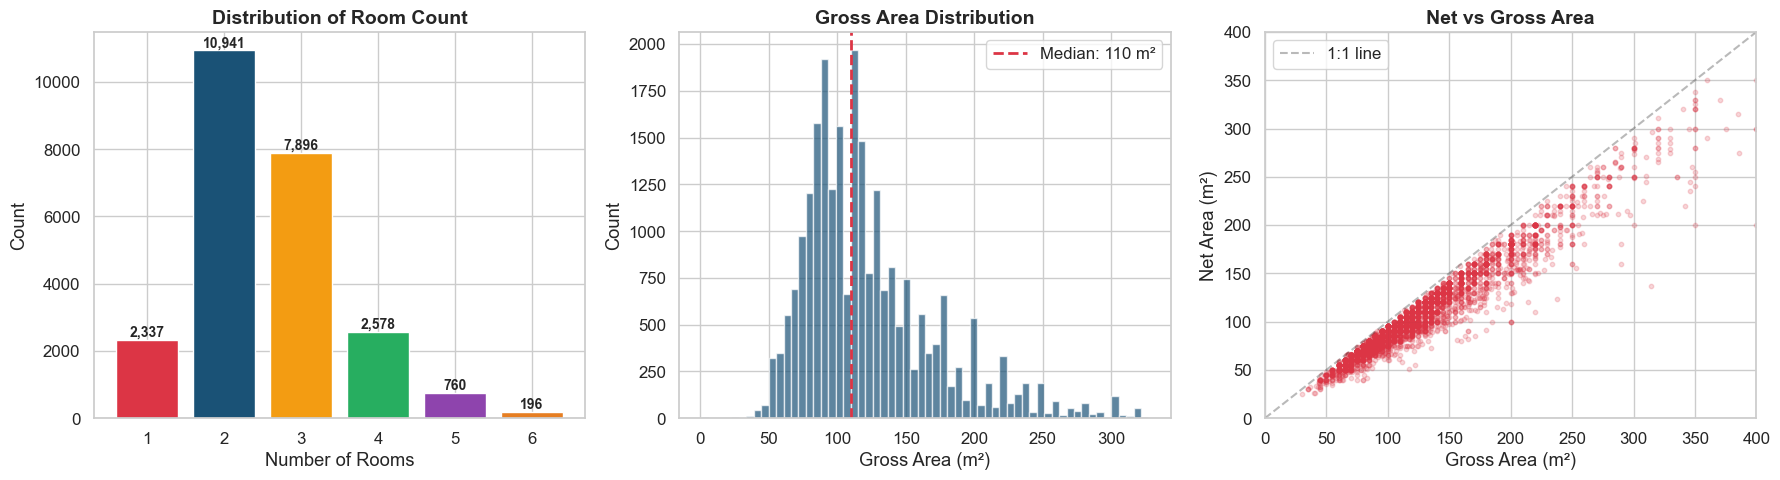


📊 2-room apartments dominate the market (44.2% of all listings)
📐 Median net/gross ratio: 87.0% — you typically get 87% of the advertised area as usable space


In [55]:
# Room distribution
room_counts = df['rooms'].value_counts().sort_index()
room_counts_main = room_counts[room_counts.index <= 6]  # Focus on 1-6 rooms

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Room count distribution
bars = axes[0].bar(room_counts_main.index, room_counts_main.values, color=PALETTE, edgecolor='white')
axes[0].set_title('Distribution of Room Count')
axes[0].set_xlabel('Number of Rooms')
axes[0].set_ylabel('Count')
for bar in bars:
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 100,
                f'{int(bar.get_height()):,}', ha='center', fontsize=10, fontweight='bold')

# Gross sqm distribution
df_sqm = df[df['gross_sqm'] <= df['gross_sqm'].quantile(0.99)]
axes[1].hist(df_sqm['gross_sqm'], bins=60, color=COLORS['secondary'], alpha=0.7, edgecolor='white')
axes[1].axvline(df['gross_sqm'].median(), color=COLORS['primary'], linestyle='--', linewidth=2,
               label=f'Median: {df["gross_sqm"].median():.0f} m²')
axes[1].set_title('Gross Area Distribution')
axes[1].set_xlabel('Gross Area (m²)')
axes[1].set_ylabel('Count')
axes[1].legend()

# Net vs Gross scatter
sample = df.sample(min(5000, len(df)), random_state=42)
axes[2].scatter(sample['gross_sqm'], sample['net_sqm'], alpha=0.2, s=10, color=COLORS['primary'])
axes[2].plot([0, 500], [0, 500], 'k--', alpha=0.3, label='1:1 line')
axes[2].set_title('Net vs Gross Area')
axes[2].set_xlabel('Gross Area (m²)')
axes[2].set_ylabel('Net Area (m²)')
axes[2].set_xlim(0, 400)
axes[2].set_ylim(0, 400)
axes[2].legend()

plt.tight_layout()
plt.show()

avg_ratio = (df['net_sqm'] / df['gross_sqm']).median()
print(f'\n📊 2-room apartments dominate the market ({room_counts_main[2]/len(df)*100:.1f}% of all listings)')
print(f'📐 Median net/gross ratio: {avg_ratio:.1%} — you typically get {avg_ratio:.0%} of the advertised area as usable space')

In [29]:
# Price vs Room count (box plot)
df_rooms = df[(df['rooms'] >= 1) & (df['rooms'] <= 6) & (df['price'] <= df['price'].quantile(0.99))]

fig = px.box(
    df_rooms,
    x='rooms',
    y='price',
    color='rooms',
    title='Price Distribution by Number of Rooms (≤99th Percentile)',
    labels={'rooms': 'Number of Rooms', 'price': 'Price (TRY)'},
    color_discrete_sequence=px.colors.qualitative.Set2
)

fig.update_layout(
    width=850, height=500,
    template='plotly_white',
    showlegend=False
)

fig.show(renderer='notebook')

[interactive Plotly figure — run the notebook to view]

In [30]:
# Price per m² vs Gross area — is bigger always cheaper per m²?
df_filtered = df[(df['gross_sqm'] <= 300) & (df['price_per_sqm'] <= df['price_per_sqm'].quantile(0.99))]

fig = px.scatter(
    df_filtered.sample(min(5000, len(df_filtered)), random_state=42),
    x='gross_sqm',
    y='price_per_sqm',
    color='rooms',
    title='Price per m² vs Apartment Size — Does Bigger Mean Cheaper per m²?',
    labels={'gross_sqm': 'Gross Area (m²)', 'price_per_sqm': 'Price per m² (TRY)', 'rooms': 'Rooms'},
    opacity=0.5,
    color_continuous_scale='Viridis'
)

fig.update_layout(width=850, height=500, template='plotly_white')
fig.show(renderer='notebook')

[interactive Plotly figure — run the notebook to view]

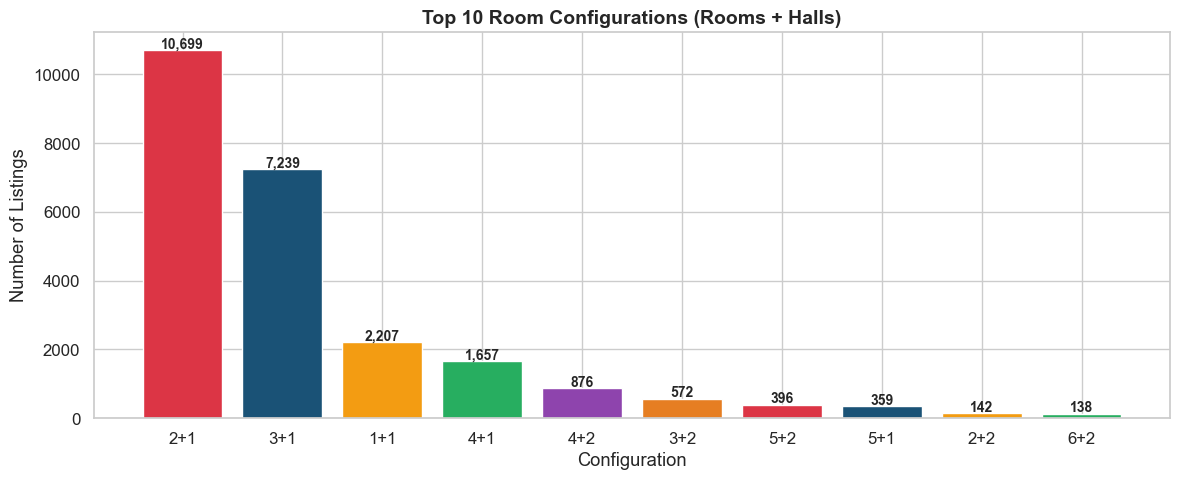


📊 The classic Turkish "2+1" (2 rooms + 1 hall) dominates with 10,699 listings
   followed by "3+1" with 7,239 listings


In [58]:
# Hall analysis — rooms + halls = total_rooms
# Most common configurations
config = df.groupby(['rooms', 'halls']).size().reset_index(name='count')
config = config.sort_values('count', ascending=False).head(10)
config['label'] = config['rooms'].astype(str) + '+' + config['halls'].astype(str)

fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.bar(config['label'], config['count'], color=PALETTE[:len(config)], edgecolor='white')
ax.set_title('Top 10 Room Configurations (Rooms + Halls)')
ax.set_xlabel('Configuration')
ax.set_ylabel('Number of Listings')

for bar in bars:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50,
            f'{int(bar.get_height()):,}', ha='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

print(f'\n📊 The classic Turkish "2+1" (2 rooms + 1 hall) dominates with {config.iloc[0]["count"]:,} listings')
print(f'   followed by "3+1" with {config.iloc[1]["count"]:,} listings')

**Size & room insights:**
- **2+1 is king** — the classic 2-bedroom + living room configuration dominates Istanbul's market
- Median apartment size is **110 m²** gross, but only about **77%** of that is usable (net) space
- Price increases with room count, but **variance also increases** — a 4-room apartment could cost ₺3M or ₺30M depending on location
- Larger apartments tend to have **lower price per m²** — economies of scale in real estate

<a id='7'></a>
## 7. 🏗️ Building Characteristics

Age, construction type, floor — how do building features relate to price?

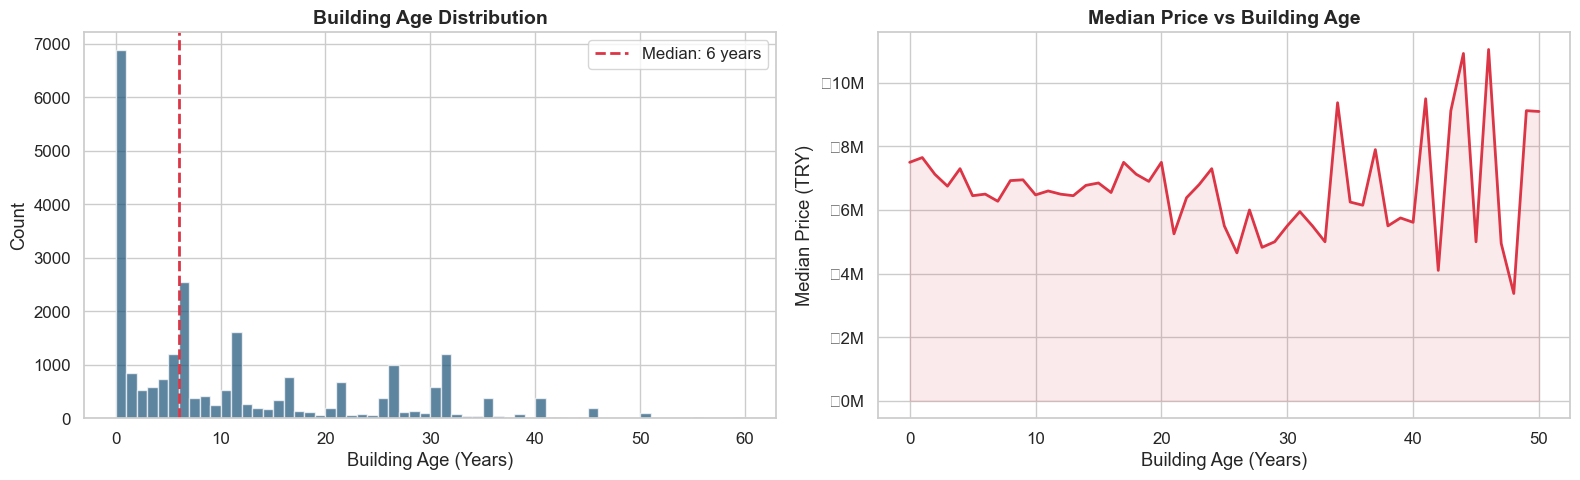


📊 27.8% of listings are brand new (age=0)
📊 New buildings command a significant premium over older ones


In [59]:
# Building age distribution
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Age distribution (capped at 60 for readability)
df_age = df[df['building_age'] <= 60]
axes[0].hist(df_age['building_age'], bins=60, color=COLORS['secondary'], alpha=0.7, edgecolor='white')
axes[0].axvline(df['building_age'].median(), color=COLORS['primary'], linestyle='--', linewidth=2,
               label=f'Median: {df["building_age"].median():.0f} years')
axes[0].set_title('Building Age Distribution')
axes[0].set_xlabel('Building Age (Years)')
axes[0].set_ylabel('Count')
axes[0].legend()

# Age vs Price
age_price = df[df['building_age'] <= 50].groupby('building_age')['price'].median()
axes[1].plot(age_price.index, age_price.values, color=COLORS['primary'], linewidth=2)
axes[1].fill_between(age_price.index, age_price.values, alpha=0.1, color=COLORS['primary'])
axes[1].set_title('Median Price vs Building Age')
axes[1].set_xlabel('Building Age (Years)')
axes[1].set_ylabel('Median Price (TRY)')
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'₺{x/1e6:.0f}M'))

plt.tight_layout()
plt.show()

brand_new_pct = (df['building_age'] == 0).mean() * 100
print(f'\n📊 {brand_new_pct:.1f}% of listings are brand new (age=0)')
print(f'📊 New buildings command a significant premium over older ones')

In [31]:
# Building condition analysis
condition = df.dropna(subset=['building_condition'])

fig = px.box(
    condition[condition['price'] <= condition['price'].quantile(0.99)],
    x='building_condition',
    y='price',
    color='building_condition',
    title=f'Price by Building Condition (n={len(condition):,} listings with data)',
    labels={'building_condition': 'Condition', 'price': 'Price (TRY)'},
    color_discrete_map={'New': COLORS['primary'], 'Second-hand': COLORS['secondary'], 'Under Construction': COLORS['accent']}
)

fig.update_layout(width=850, height=500, template='plotly_white', showlegend=False)
fig.show(renderer='notebook')

for cond in condition['building_condition'].unique():
    med = condition[condition['building_condition'] == cond]['price'].median()
    cnt = (condition['building_condition'] == cond).sum()
    print(f'  {cond:25s}: Median ₺{med/1e6:.1f}M  (n={cnt:,})')

[interactive Plotly figure — run the notebook to view]

  New                      : Median ₺7.8M  (n=3,453)
  Second-hand              : Median ₺6.7M  (n=7,299)
  Under Construction       : Median ₺9.3M  (n=168)


In [32]:
# Floor analysis
floor_data = df.dropna(subset=['floor'])
floor_data = floor_data[(floor_data['floor'] >= -2) & (floor_data['floor'] <= 25)]

floor_price = floor_data.groupby('floor').agg(
    median_price=('price', 'median'),
    count=('price', 'count')
).reset_index()

floor_price = floor_price[floor_price['count'] >= 20]  # min 20 listings

fig = make_subplots(specs=[[{'secondary_y': True}]])

fig.add_trace(
    go.Bar(x=floor_price['floor'], y=floor_price['count'], name='Listing Count',
           marker_color=COLORS['secondary'], opacity=0.6),
    secondary_y=False
)

fig.add_trace(
    go.Scatter(x=floor_price['floor'], y=floor_price['median_price'], name='Median Price',
               mode='lines+markers', line=dict(color=COLORS['primary'], width=3),
               marker=dict(size=8)),
    secondary_y=True
)

fig.update_layout(
    title='Floor Number vs Price & Listing Count',
    xaxis_title='Floor Number',
    width=850, height=500,
    template='plotly_white'
)
fig.update_yaxes(title_text='Number of Listings', secondary_y=False)
fig.update_yaxes(title_text='Median Price (TRY)', secondary_y=True)

fig.show(renderer='notebook')

[interactive Plotly figure — run the notebook to view]

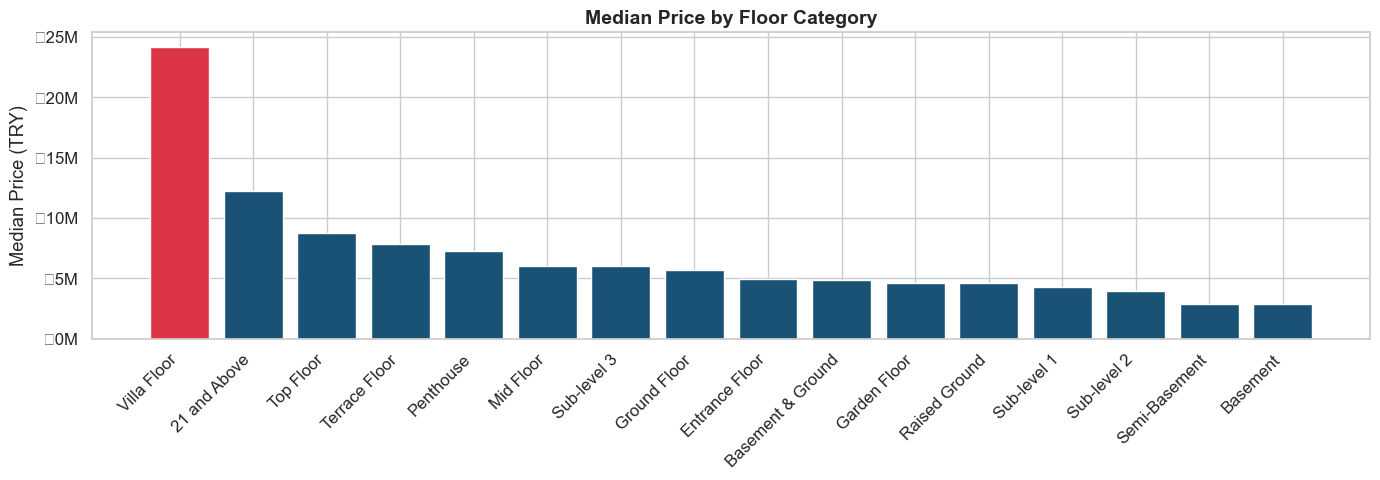

In [62]:
# Floor category analysis
floor_cat = df.dropna(subset=['floor_category'])
floor_cat_price = floor_cat.groupby('floor_category')['price'].median().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(14, 5))
colors = [COLORS['primary'] if v == floor_cat_price.max() else COLORS['secondary'] for v in floor_cat_price.values]
ax.bar(floor_cat_price.index, floor_cat_price.values, color=colors, edgecolor='white')
ax.set_title('Median Price by Floor Category')
ax.set_xlabel('')
ax.set_ylabel('Median Price (TRY)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'₺{x/1e6:.0f}M'))
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

**Building insights:**
- A **huge spike at age=0** — a significant chunk of Istanbul's market is new construction
- New buildings command a clear **price premium** over second-hand ones
- Higher floors generally correlate with higher prices, with **penthouses and terrace floors** at the premium end
- Most listings are concentrated on floors 1-10, with a sharp dropoff above floor 15

<a id='8'></a>
## 8. 🔎 Feature Deep Dive — What Else Matters?

Let's explore heating, furnishing, complex membership, deed type, and other features.

In [23]:
# Heating type analysis
heating = df['heating_type'].value_counts()

fig = px.pie(
    values=heating.values,
    names=heating.index,
    title='Heating Type Distribution',
    color_discrete_sequence=px.colors.qualitative.Set3,
    hole=0.35
)

fig.update_layout(width=850, height=500, template='plotly_white')
fig.update_traces(textposition='inside', textinfo='percent+label')
fig.show(renderer='notebook')

print(f'📊 Combi Boiler dominates with {heating.iloc[0]/len(df)*100:.1f}% of all listings')

[interactive Plotly figure — run the notebook to view]

📊 Combi Boiler dominates with 74.6% of all listings


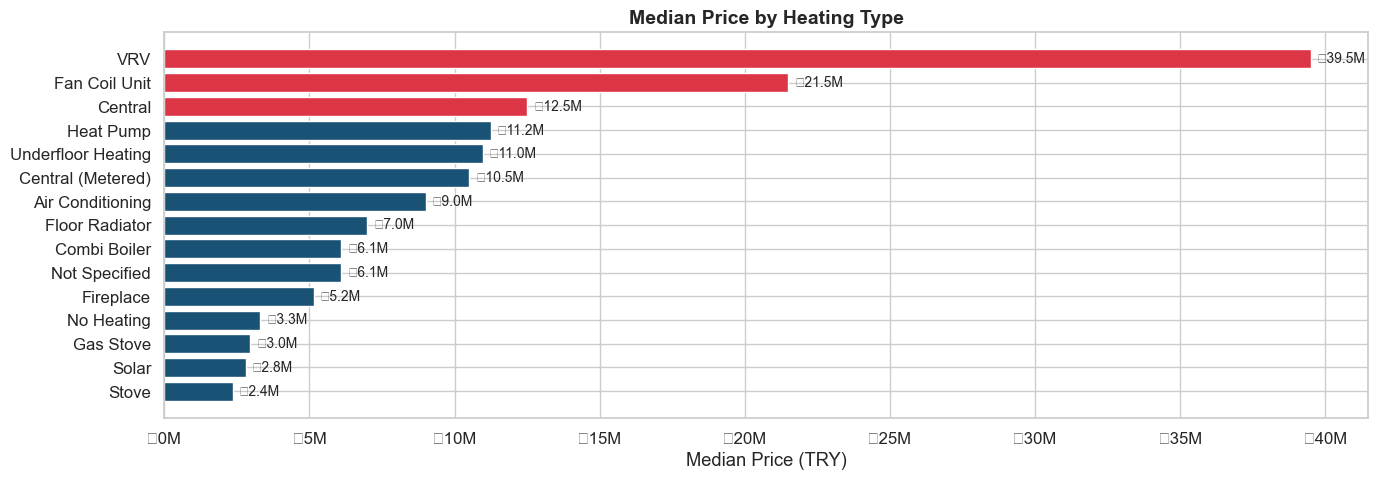

In [64]:
# Heating type vs price
heating_price = df.groupby('heating_type')['price'].median().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(14, 5))
colors = [COLORS['primary'] if i < 3 else COLORS['secondary'] for i in range(len(heating_price))]
ax.barh(heating_price.index[::-1], heating_price.values[::-1], color=colors[::-1], edgecolor='white')
ax.set_title('Median Price by Heating Type')
ax.set_xlabel('Median Price (TRY)')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'₺{x/1e6:.0f}M'))

for i, (val, name) in enumerate(zip(heating_price.values[::-1], heating_price.index[::-1])):
    ax.text(val + 200000, i, f'₺{val/1e6:.1f}M', va='center', fontsize=10)

plt.tight_layout()
plt.show()

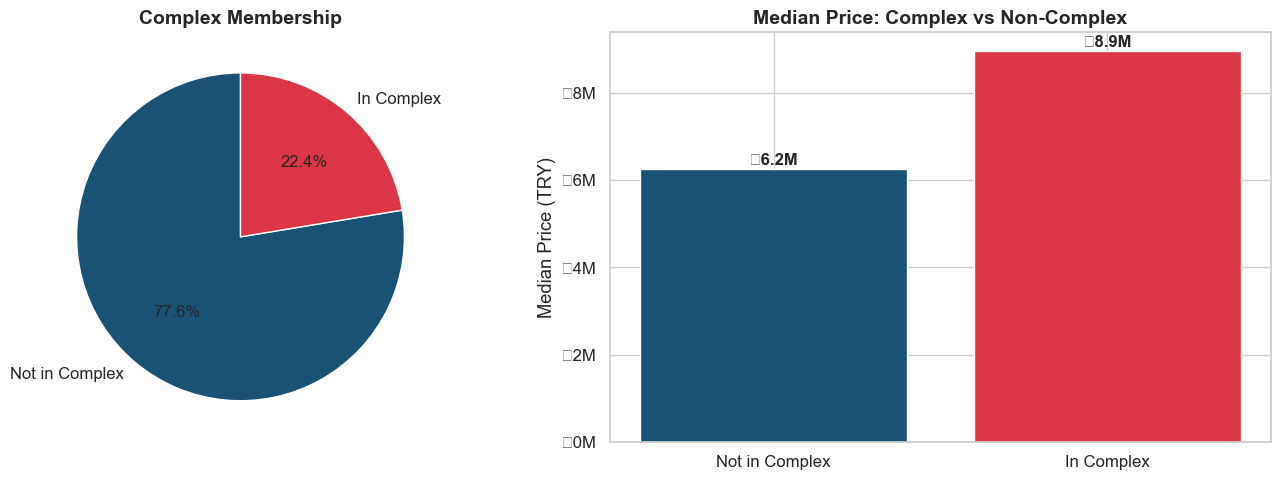


📊 Complex apartments carry a 43% price premium over non-complex ones


In [65]:
# Complex membership — does living in a complex cost more?
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Count
complex_counts = df['is_in_complex'].value_counts()
labels = ['Not in Complex', 'In Complex']
axes[0].pie(complex_counts.values, labels=labels, autopct='%1.1f%%',
           colors=[COLORS['secondary'], COLORS['primary']], startangle=90,
           textprops={'fontsize': 12})
axes[0].set_title('Complex Membership')

# Price comparison
complex_price = df[df['price'] <= df['price'].quantile(0.99)].groupby('is_in_complex')['price'].median()
bars = axes[1].bar(labels, complex_price.values, color=[COLORS['secondary'], COLORS['primary']], edgecolor='white')
axes[1].set_title('Median Price: Complex vs Non-Complex')
axes[1].set_ylabel('Median Price (TRY)')
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'₺{x/1e6:.0f}M'))

for bar in bars:
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 100000,
                f'₺{bar.get_height()/1e6:.1f}M', ha='center', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

premium = (complex_price[1] / complex_price[0] - 1) * 100
print(f'\n📊 Complex apartments carry a {premium:.0f}% price premium over non-complex ones')

In [33]:
# Furnished vs Unfurnished
furnished = df.dropna(subset=['furnished'])
furn_price = furnished[furnished['price'] <= furnished['price'].quantile(0.99)]

fig = px.box(
    furn_price,
    x='furnished',
    y='price',
    color='furnished',
    title=f'Price by Furnishing Status (n={len(furnished):,})',
    labels={'furnished': '', 'price': 'Price (TRY)'},
    color_discrete_map={'Furnished': COLORS['primary'], 'Unfurnished': COLORS['secondary']}
)

fig.update_layout(width=850, height=500, template='plotly_white', showlegend=False)
fig.show(renderer='notebook')

for f in furnished['furnished'].unique():
    med = furnished[furnished['furnished'] == f]['price'].median()
    print(f'  {f:15s}: Median ₺{med/1e6:.1f}M')

[interactive Plotly figure — run the notebook to view]

[interactive Plotly figure — run the notebook to view]

  Furnished      : Median ₺6.2M
  Unfurnished    : Median ₺6.8M


In [34]:
# Deed status analysis
deed = df['deed_status'].value_counts()

fig = px.bar(
    x=deed.index,
    y=deed.values,
    title='Deed Status Distribution',
    labels={'x': 'Deed Status', 'y': 'Count'},
    color=deed.values,
    color_continuous_scale='Blues'
)

fig.update_layout(
    width=850, height=500,
    template='plotly_white',
    coloraxis_showscale=False,
    xaxis_tickangle=-30
)

fig.show(renderer='notebook')

print(f'📊 {deed.iloc[0]/len(df)*100:.1f}% of listings have Condominium Title — the most common and secure deed type')

[interactive Plotly figure — run the notebook to view]

📊 63.5% of listings have Condominium Title — the most common and secure deed type


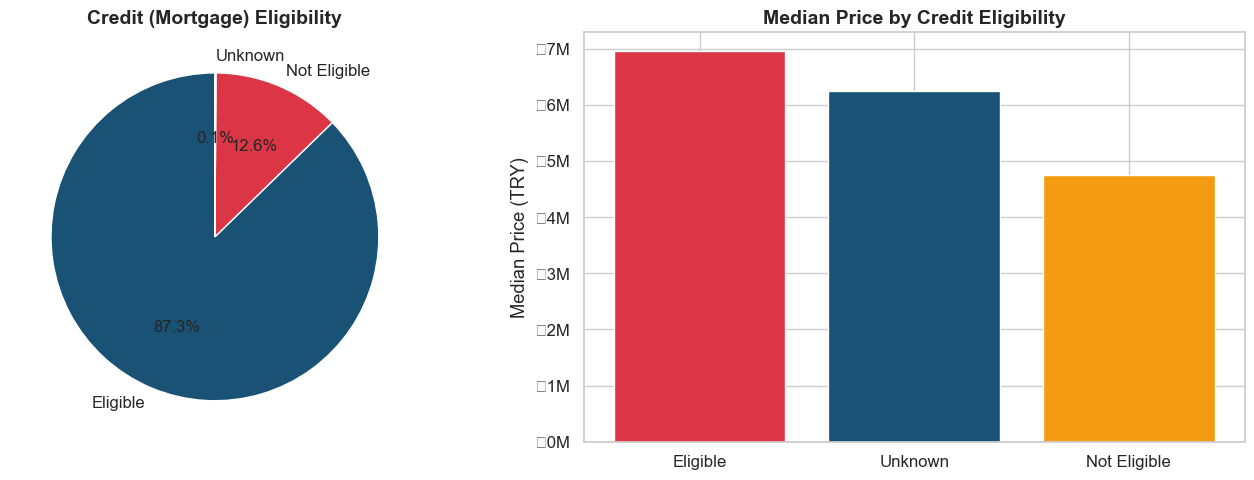


📊 87.3% of apartments are mortgage-eligible


In [68]:
# Credit eligibility
credit = df['credit_eligible'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Distribution
axes[0].pie(credit.values, labels=credit.index, autopct='%1.1f%%',
           colors=[COLORS['secondary'], COLORS['primary'], COLORS['light']],
           startangle=90, textprops={'fontsize': 12})
axes[0].set_title('Credit (Mortgage) Eligibility')

# Price by credit eligibility
credit_price = df[df['price'] <= df['price'].quantile(0.99)].groupby('credit_eligible')['price'].median()
credit_price = credit_price.sort_values(ascending=False)
axes[1].bar(credit_price.index, credit_price.values,
           color=[COLORS['primary'], COLORS['secondary'], COLORS['accent']], edgecolor='white')
axes[1].set_title('Median Price by Credit Eligibility')
axes[1].set_ylabel('Median Price (TRY)')
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'₺{x/1e6:.0f}M'))

plt.tight_layout()
plt.show()

print(f'\n📊 {credit.iloc[0]/len(df)*100:.1f}% of apartments are mortgage-eligible')

In [69]:
# Usage status analysis
usage = df.dropna(subset=['usage_status'])
usage_price = usage.groupby('usage_status').agg(
    median_price=('price', 'median'),
    count=('price', 'count')
).sort_values('count', ascending=False)

print('📊 Usage Status Summary:')
print(f'{"Status":<20} {"Count":>8} {"Share":>8} {"Median Price":>15}')
print('='*55)
for idx, row in usage_price.iterrows():
    print(f'{idx:<20} {row["count"]:>8,} {row["count"]/len(usage)*100:>7.1f}% ₺{row["median_price"]/1e6:>10.1f}M')

📊 Usage Status Summary:
Status                  Count    Share    Median Price
Vacant               14,015.0    58.1% ₺       7.2M
Tenant-occupied       5,099.0    21.1% ₺       5.8M
Owner-occupied        4,933.0    20.4% ₺       6.7M
Not Specified            86.0     0.4% ₺       5.4M


In [35]:
# Orientation analysis — which direction do Istanbul apartments face?
orientation = df.dropna(subset=['orientation'])
orient_counts = orientation['orientation'].value_counts().head(10)

fig = px.bar(
    x=orient_counts.values,
    y=orient_counts.index,
    orientation='h',
    title=f'Top 10 Apartment Orientations (n={len(orientation):,})',
    labels={'x': 'Count', 'y': 'Orientation'},
    color=orient_counts.values,
    color_continuous_scale='Reds'
)

fig.update_layout(width=850, height=500, template='plotly_white', coloraxis_showscale=False)
fig.show(renderer='notebook')

[interactive Plotly figure — run the notebook to view]

**Feature insights:**
- **Combi Boiler** is the dominant heating type (74%), but **underfloor heating** and **VRV** systems correlate with higher prices (luxury segment)
- Living in a **residential complex** carries a noticeable price premium
- **63.5%** of apartments have Condominium Title — the gold standard for deed security
- **87%** of listings are mortgage-eligible — a healthy, financeable market
- **South-facing** apartments (more sunlight) tend to be slightly more common, aligning with Turkish preference for sun exposure

<a id='9'></a>
## 9. 📈 Correlation & Feature Relationships

Which features are most predictive of price? Let's examine the correlations and interactions.

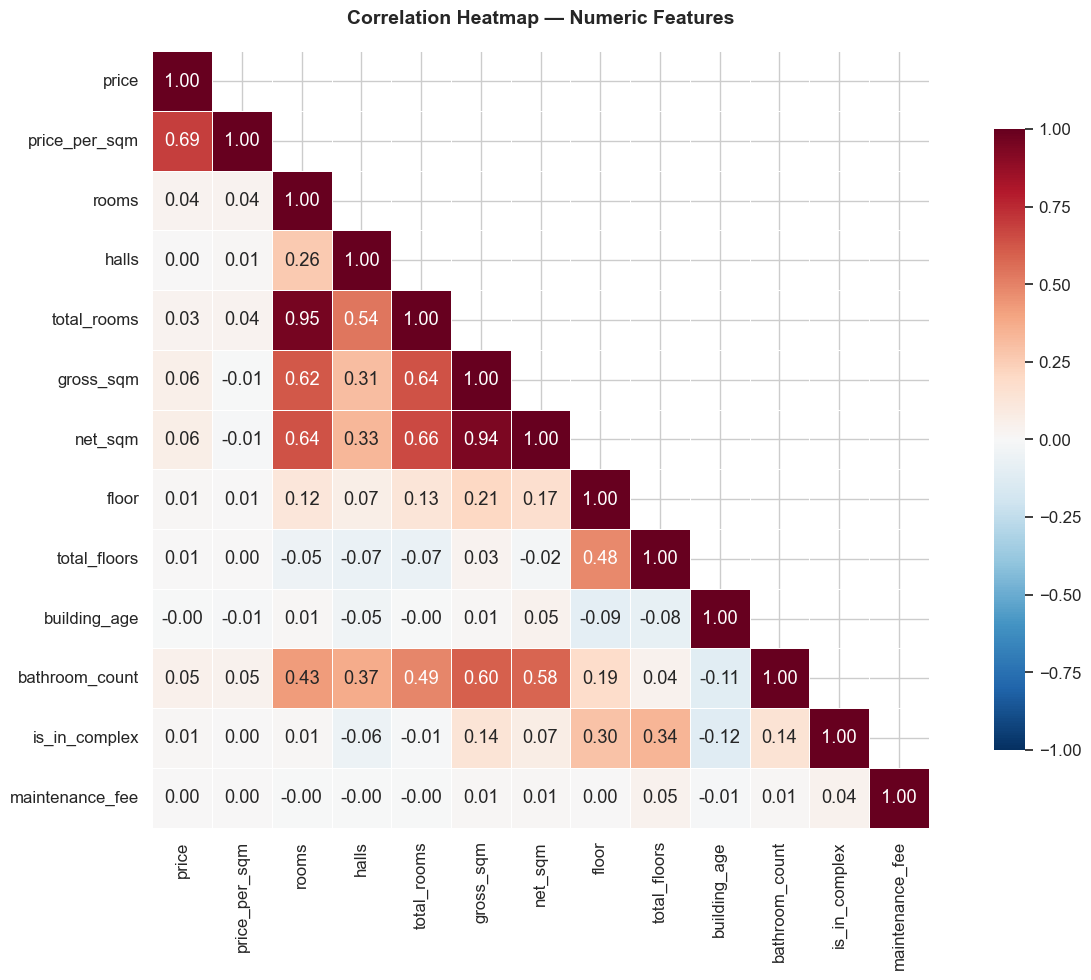

In [71]:
# Correlation heatmap for numeric features
numeric_cols = ['price', 'price_per_sqm', 'rooms', 'halls', 'total_rooms',
                'gross_sqm', 'net_sqm', 'floor', 'total_floors',
                'building_age', 'bathroom_count', 'is_in_complex', 'maintenance_fee']

corr_matrix = df[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(14, 10))

mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)

sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt='.2f',
    cmap='RdBu_r',
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={'shrink': 0.8},
    ax=ax,
    vmin=-1, vmax=1
)

ax.set_title('Correlation Heatmap — Numeric Features', fontsize=14, fontweight='bold', pad=20)

plt.tight_layout()
plt.show()

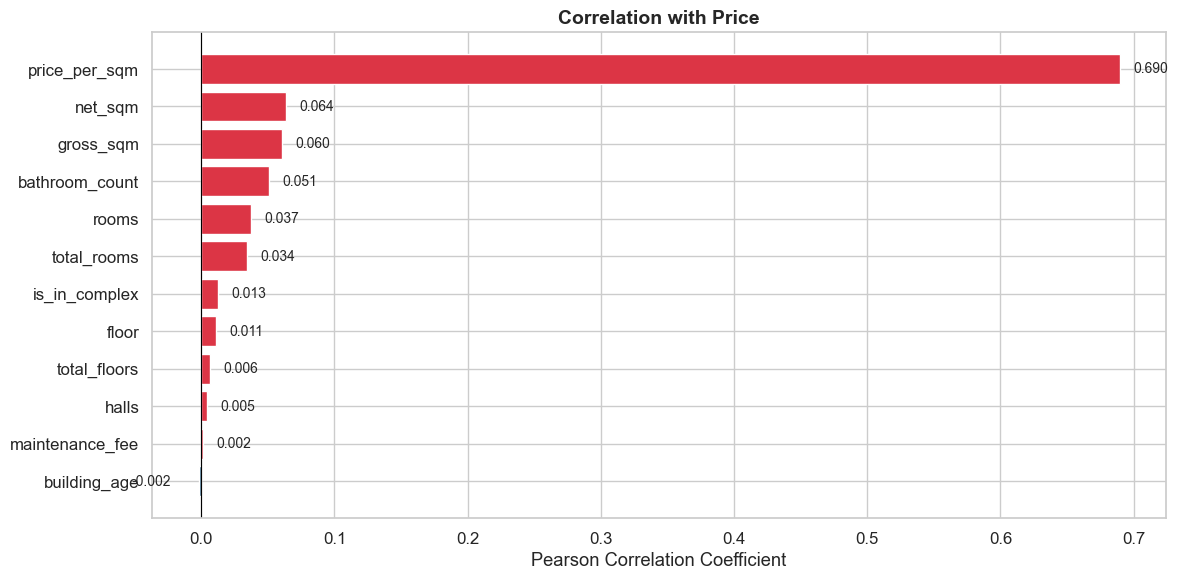


📊 Top 3 correlates with price: price_per_sqm (0.690), net_sqm (0.064), gross_sqm (0.060)
💡 Low linear correlations suggest non-linear relationships — tree-based models may outperform linear regression


In [72]:
# Feature correlations with price (sorted)
price_corr = corr_matrix['price'].drop('price').sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(12, 6))

colors = [COLORS['primary'] if v > 0 else COLORS['secondary'] for v in price_corr.values]
ax.barh(price_corr.index[::-1], price_corr.values[::-1], color=colors[::-1], edgecolor='white')
ax.set_title('Correlation with Price')
ax.set_xlabel('Pearson Correlation Coefficient')
ax.axvline(x=0, color='black', linewidth=0.8)

for i, (val, name) in enumerate(zip(price_corr.values[::-1], price_corr.index[::-1])):
    ax.text(val + 0.01 if val > 0 else val - 0.05, i, f'{val:.3f}', va='center', fontsize=10)

plt.tight_layout()
plt.show()

print(f'\n📊 Top 3 correlates with price: price_per_sqm ({price_corr.iloc[0]:.3f}), net_sqm ({price_corr.iloc[1]:.3f}), gross_sqm ({price_corr.iloc[2]:.3f})')
print(f'💡 Low linear correlations suggest non-linear relationships — tree-based models may outperform linear regression')

In [36]:
# District as price predictor — median encoding
district_encoded = df.groupby('district')['price'].median()
df['district_median_price'] = df['district'].map(district_encoded)

corr_with_district = df[['price', 'district_median_price']].corr().iloc[0, 1]

fig = px.scatter(
    df.sample(5000, random_state=42),
    x='district_median_price',
    y='price',
    opacity=0.3,
    title=f'District (median-encoded) vs Price — Correlation: {corr_with_district:.3f}',
    labels={'district_median_price': 'District Median Price (TRY)', 'price': 'Listing Price (TRY)'},
    trendline='ols'
)

fig.update_layout(width=850, height=500, template='plotly_white')
fig.show(renderer='notebook')

df.drop(columns=['district_median_price'], inplace=True)

print(f'\n📊 District alone (median-encoded) has a {corr_with_district:.3f} correlation with price')
print(f'💡 Location is the STRONGEST predictor of apartment price in Istanbul')

[interactive Plotly figure — run the notebook to view]


📊 District alone (median-encoded) has a 0.055 correlation with price
💡 Location is the STRONGEST predictor of apartment price in Istanbul


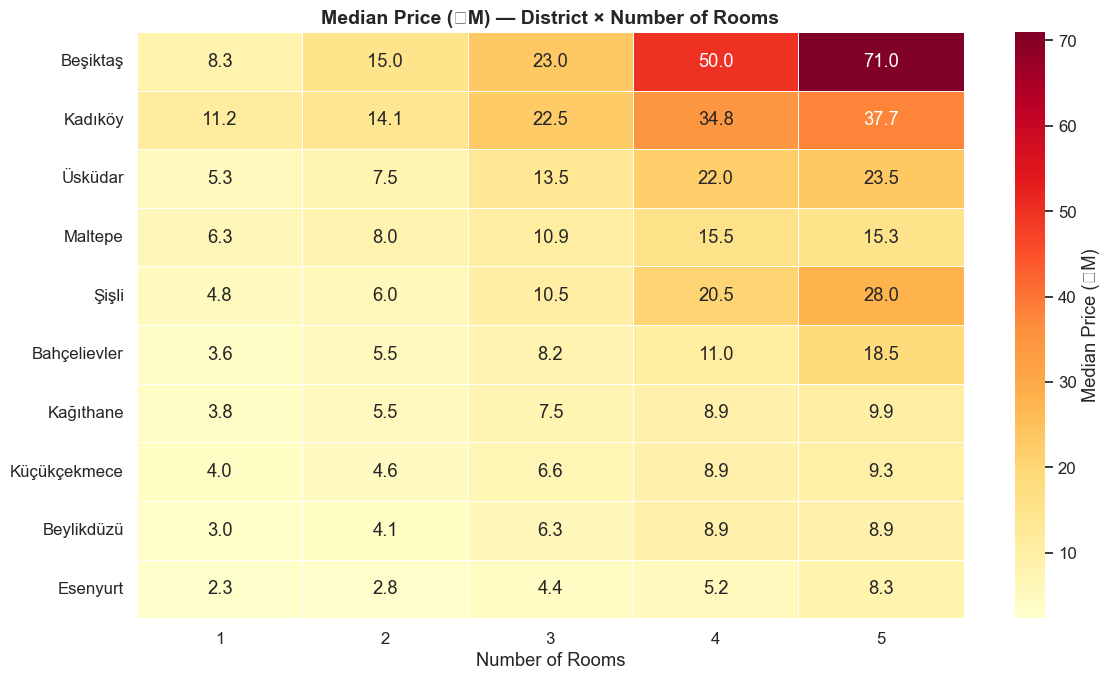


📊 This heatmap is a powerful summary: the color intensity shows how district and room count jointly drive price


In [74]:
# Multi-feature interaction: District × Rooms → Price heatmap
# Top 10 districts by listing count, rooms 1-5
top_districts = df['district'].value_counts().head(10).index.tolist()
df_heatmap = df[(df['district'].isin(top_districts)) & (df['rooms'].between(1, 5))]

pivot = df_heatmap.groupby(['district', 'rooms'])['price'].median().reset_index()
pivot = pivot.pivot(index='district', columns='rooms', values='price')

# Sort districts by overall median price
district_order = df_heatmap.groupby('district')['price'].median().sort_values(ascending=False).index
pivot = pivot.reindex(district_order)

fig, ax = plt.subplots(figsize=(12, 7))

sns.heatmap(
    pivot / 1e6,  # Convert to millions
    annot=True,
    fmt='.1f',
    cmap='YlOrRd',
    linewidths=0.5,
    ax=ax,
    cbar_kws={'label': 'Median Price (₺M)'}
)

ax.set_title('Median Price (₺M) — District × Number of Rooms', fontsize=14, fontweight='bold')
ax.set_xlabel('Number of Rooms')
ax.set_ylabel('')

plt.tight_layout()
plt.show()

print(f'\n📊 This heatmap is a powerful summary: the color intensity shows how district and room count jointly drive price')

**Correlation & interaction insights:**
- **price_per_sqm** has the highest linear correlation with price (0.69) — makes sense, they're derived from the same base
- Physical features (sqm, rooms) have **surprisingly low linear correlations** with price — this is because **location dominates**
- When we median-encode district, it becomes the **single strongest predictor**
- The **District × Rooms heatmap** reveals the full picture: a 2-room apartment in Kadıköy costs more than a 5-room apartment in Esenyurt
- **Key takeaway for modeling**: Tree-based models (XGBoost, LightGBM) will likely outperform linear models due to non-linear feature interactions

<a id='10'></a>
## 10. 🎯 Key Findings & Conclusions

After exploring 24,767 apartment listings across Istanbul, here are the key takeaways:

### 💰 Price
- Median apartment price: **₺6.75M** (~$190K USD), heavily right-skewed
- Log-transformation yields a near-normal distribution — ideal for regression models
- ~5% of listings are statistical outliers; a few extreme entries (>₺500M) are likely errors

### 📍 Location Is King
- **Bakırköy, Beşiktaş, Kadıköy** are the premium trio — median prices 4-8x above the cheapest districts
- **Esenyurt** is the most affordable — high-density suburban development
- District alone (median-encoded) is the **strongest single predictor** of price
- A 2-room apartment in a premium district costs more than a 5-room apartment in a budget district

### 📐 Size & Layout
- The **2+1 configuration** (2 rooms + 1 hall) dominates the market at 44%
- Median apartment size: 110m² gross, ~85m² net (77% usable ratio)
- Larger apartments have lower price per m² — economies of scale exist

### 🏗️ Building Features
- New construction commands a **significant premium** over older buildings
- Higher floors and penthouses/terrace floors are priced higher
- Living in a **residential complex** adds a notable price premium

### 🤖 Modeling Implications
- Low linear correlations + strong location effects → **tree-based models recommended**
- Target encoding for district/neighborhood could be very powerful
- Log-transform the target variable for regression
- Several features have >50% missing values — careful imputation or model-based handling needed

---
